# StorSeismic Section 4: Field Data Workflow (Mobil AVO Viking Graben Line 12 + OpenFWI)

Finalized `nb3_1_mobil_openfwi.ipynb` aligned with the validated `nb3_2` / `nb3_3` / `nb3_4` pipeline, evaluating **OpenFWI (CurveVel-A, Synthetic)** + **Mobil AVO Viking Graben Line 12 (2D Marine Field Data)**:
1. **Stage 1:** Self-supervised MLM pre-training (`BERT_MINI`, 15% masking with random + contiguous-gap spans, 50/50 OpenFWI + Mobil mix, best-checkpoint saving).
2. **Stage 2:** Supervised fine-tuning with partial layer freezing (`k=2`) for **Domain-Mixed Denoising** (OpenFWI + 25% Mobil Gaussian-noise preservation) and **1D Velocity Prediction** (token-0 head, best-checkpoint saving).
3. **Stage 3:** Inference, $f-k$ spectral decomposition, 2D velocity cross-section, $V_p$ parity scatter, zero-shot trace interpolation (Exp B2), and 16-head attention dissection.

### Key Strategies Applied (Aligned with `nb3_2` v2)
- **Domain-Mixed Stage 2A Denoising (`DENOISE_FIELD_MIX_RATIO = 0.25`):** Mixes 25% Mobil-train + Gaussian noise samples during Stage 2A training (while validating strictly on OpenFWI `s_test`) to eliminate the synthetic-to-field denoising collapse (`r ≈ -0.0008`, `100.82%` removed energy) while retaining high OpenFWI SNR.
- **Unified Peak-Abs Normalization `[-1, 1]`:** Both Mobil AVO and OpenFWI use `normalize_gather` so Stage 1 reconstructs a single consistent amplitude scale.
- **Best-Checkpoint Saving (All Stages):** Tracks and reloads the lowest test-loss checkpoint for Stages 1, 2A, and 2B before downstream fine-tuning and inference.
- **Contiguous-Gap MLM & Horizontal-Flip Augmentation:** Includes horizontal trace-flip (`p=0.5`) and 3–6 trace contiguous gaps on 30% of Stage 1 training gathers to strengthen zero-shot dead-trace & gap interpolation.
- **Averaged Zero-Shot Interpolation & Full 10-Plot Suite:** Averages zero-shot MLM predictions over `n_avg=5` draws and exports all 10 300-DPI report figures plus `ablation_frozen_bundle.npz` and `ablation_config.json` to `./results/mobil_openfwi_section4/`.

### Expected Data Paths
- `./data/mobil/seismic.segy`
- `./data/openfwi/data1.npy`
- `./data/openfwi/model1.npy`

In [1]:
import os
import math
import json
import numpy as np
import segyio
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, resample
from scipy.interpolate import interp1d

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Reproducibility & Device
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Paths (relative to storseismic/ directory)
MOBIL_SEGY_PATH = "./data/mobil/seismic.segy"
OPENFWI_DATA_PATH = "./data/openfwi/data1.npy"
OPENFWI_MODEL_PATH = "./data/openfwi/model1.npy"
SAVE_DIR = "./results/mobil_openfwi_section4"
os.makedirs(SAVE_DIR, exist_ok=True)

# Hyperparameters (BERT_MINI)
N_TRACES = 70
N_TIME = 256
HIDDEN_DIM = 256
NUM_LAYERS = 4
NUM_HEADS = 4
MASK_RATIO = 0.15
LR = 5e-4

# Domain-mixed denoising setting (prevents Mobil field reflection collapse in Stage 2A)
DENOISE_FIELD_MIX_RATIO = 0.25

RUN_TRAINING = True  # Set True on first run to train & save; False to load saved checkpoints
PRETRAIN_EPOCHS = 300
FINETUNE_DENOISE_EPOCHS = 250
FINETUNE_VEL_EPOCHS = 250
HISTORY_PATH = os.path.join(SAVE_DIR, "training_history.npz")

Using device: cuda


## 1. Load & Preprocess Mobil AVO Viking Graben Line 12 (2D Marine) + OpenFWI Synthetic Data

In [2]:
def highpass_filter(data, cutoff=4.0, fs=250.0, order=4):
    """4 Hz marine high-pass filter to suppress low-frequency swell noise (Section 5 of paper)."""
    nyq = 0.5 * fs
    b, a = butter(order, cutoff / nyq, btype="high", analog=False)
    return filtfilt(b, a, data, axis=-1)


def normalize_gather(gather):
    """Per-gather peak-absolute normalization strictly to [-1, 1] (unified across synthetic & field)."""
    max_val = np.max(np.abs(gather)) + 1e-8
    return (gather / max_val).astype(np.float32)


def load_mobil_gathers(segy_path, target_traces=70, target_time=256, max_shots=500):
    """
    Load Mobil AVO Viking Graben Line 12 (1001 shots x 120 traces x 1500 samples @ 4ms).
    Applies 4 Hz high-pass filter, uniformly subsamples 120 -> 70 traces, takes first
    1000 samples (4.0 s), resamples to 256 samples (64.0 Hz), and peak-normalizes to [-1, 1].
    """
    if not os.path.exists(segy_path):
        raise FileNotFoundError(f"Mobil SEG-Y file not found at: {segy_path}")

    gathers = []
    with segyio.open(segy_path, "r", ignore_geometry=True) as f:
        dt_us = f.bin[segyio.BinField.Interval]
        fs_raw = 1e6 / float(dt_us) if dt_us > 0 else 250.0
        traces_per_shot = 120
        n_shots = min(f.tracecount // traces_per_shot, max_shots)
        trace_idx = np.linspace(0, traces_per_shot - 1, target_traces, dtype=int)
        for s in range(n_shots):
            start = s * traces_per_shot
            shot = np.array([f.trace[i] for i in range(start, start + traces_per_shot)], dtype=np.float32)
            shot = highpass_filter(shot, cutoff=4.0, fs=fs_raw, order=4)
            shot = shot[trace_idx, :]
            shot = resample(shot[:, :1000], target_time, axis=1)
            gathers.append(normalize_gather(shot))

    fs_resampled = fs_raw * (target_time / 1000.0)
    print(f"Loaded {len(gathers)} Mobil AVO shot gathers (raw fs={fs_raw:.1f} Hz -> resampled fs={fs_resampled:.1f} Hz)")
    return np.array(gathers, dtype=np.float32), fs_resampled


def load_openfwi_data(data_path, model_path, num_gathers=500, target_time=256):
    if not os.path.exists(data_path) or not os.path.exists(model_path):
        raise FileNotFoundError(f"OpenFWI files not found. Expected: {data_path} and {model_path}")

    raw_data = np.load(data_path)    # (500, 5, 1000, 70)
    raw_model = np.load(model_path)  # (500, 1, 70, 70)

    gathers = []
    vels = []
    for i in range(min(num_gathers, len(raw_data))):
        g = raw_data[i, 2].T  # middle shot (70, 1000)
        g_res = resample(g, target_time, axis=1)
        gathers.append(normalize_gather(g_res))
        v_1d = raw_model[i, 0].mean(axis=1)  # (70,)
        vels.append(v_1d)

    return np.array(gathers, dtype=np.float32), np.array(vels, dtype=np.float32)


synth_gathers, synth_vels = load_openfwi_data(OPENFWI_DATA_PATH, OPENFWI_MODEL_PATH, num_gathers=500, target_time=N_TIME)
field_gathers, FS_MOBIL = load_mobil_gathers(MOBIL_SEGY_PATH, target_traces=N_TRACES, target_time=N_TIME, max_shots=len(synth_gathers))

# Match sample counts for exact 50/50 split
n_samples = min(len(field_gathers), len(synth_gathers))
field_gathers = field_gathers[:n_samples]
synth_gathers = synth_gathers[:n_samples]
synth_vels = synth_vels[:n_samples]

VEL_MIN = float(synth_vels.min())
VEL_MAX = float(synth_vels.max())
synth_vels_norm = (synth_vels - VEL_MIN) / (VEL_MAX - VEL_MIN + 1e-8)

print(f"Field (Mobil) shape   : {field_gathers.shape} | Amp range: [{field_gathers.min():.3f}, {field_gathers.max():.3f}]")
print(f"Synth (OpenFWI) shape : {synth_gathers.shape} | Amp range: [{synth_gathers.min():.3f}, {synth_gathers.max():.3f}]")
print(f"Synth Velocity shape  : {synth_vels.shape} | Range: [{VEL_MIN:.1f}, {VEL_MAX:.1f}] m/s")

Loaded 500 Mobil AVO shot gathers (raw fs=250.0 Hz -> resampled fs=64.0 Hz)
Field (Mobil) shape   : (500, 70, 256) | Amp range: [-1.000, 1.000]
Synth (OpenFWI) shape : (500, 70, 256) | Amp range: [-0.532, 1.000]
Synth Velocity shape  : (500, 70) | Range: [1503.0, 4478.4] m/s


## 2. PyTorch Datasets & Augmentations

In [3]:
class PretrainDataset(Dataset):
    """
    Self-supervised MLM dataset mixing 50% OpenFWI Synthetic + 50% Mobil Field data.
    If field_data has fewer gathers than synth_data, field_data is tiled so both domains contribute 50/50.
    Augmentations: polarity reversal, spatial trace-order flip, slight time shift, and BERT-style 15% masking
    (70% random trace masking + 30% contiguous 3-6 trace gap + random traces during training).
    """
    def __init__(self, synth_data, field_data, mask_ratio=0.15, augment=True, gap_aug_prob=0.30):
        if len(field_data) < len(synth_data):
            reps = int(np.ceil(len(synth_data) / len(field_data)))
            field_balanced = np.tile(field_data, (reps, 1, 1))[:len(synth_data)]
        else:
            field_balanced = field_data[:len(synth_data)]
        self.data = np.concatenate([synth_data, field_balanced], axis=0)
        self.mask_ratio = mask_ratio
        self.augment = augment
        self.gap_aug_prob = gap_aug_prob

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        x = self.data[idx].copy()  # (X, T)

        if self.augment:
            if np.random.rand() < 0.5:
                x = -x
            if np.random.rand() < 0.5:
                x = x[::-1].copy()  # physically valid horizontal flip
            shift = np.random.randint(-5, 6)
            if shift != 0:
                x = np.roll(x, shift, axis=1)

        label = x.copy()
        n_traces = x.shape[0]
        n_mask = max(1, int(round(n_traces * self.mask_ratio)))

        # Mix standard random masking with contiguous gap masking to strengthen zero-shot gap interpolation
        if self.augment and np.random.rand() < self.gap_aug_prob:
            gap_len = np.random.randint(3, min(7, n_mask + 1))
            gap_start = np.random.randint(2, n_traces - gap_len - 2)
            gap_idx = np.arange(gap_start, gap_start + gap_len)
            remaining = n_mask - gap_len
            if remaining > 0:
                avail = np.setdiff1d(np.arange(n_traces), gap_idx)
                extra_idx = np.random.choice(avail, size=remaining, replace=False)
                mask_idx = np.concatenate([gap_idx, extra_idx])
            else:
                mask_idx = gap_idx
        else:
            mask_idx = np.random.choice(n_traces, size=n_mask, replace=False)

        mask = np.zeros(n_traces, dtype=np.float32)
        mask[mask_idx] = 1.0

        for m in mask_idx:
            p = np.random.rand()
            if p < 0.8:
                x[m] = np.random.normal(0.0, 0.3, size=x.shape[1]).astype(np.float32)
            elif p < 0.9:
                rand_trace = np.random.randint(0, n_traces)
                x[m] = label[rand_trace]
            # else 10%: keep original trace unchanged

        return torch.tensor(x, dtype=torch.float32), torch.tensor(label, dtype=torch.float32), torch.tensor(mask, dtype=torch.float32)


class DenoiseDataset(Dataset):
    """
    Domain-mixed supervised denoising dataset:
    - Primary: clean OpenFWI synthetic gathers + additive Gaussian noise (sigma in {0.10, 0.20}).
    - Optional field preservation (when field_data is passed during training): mixes in
      field_mix_ratio of Mobil train gathers + Gaussian noise (sigma in {0.05, 0.10, 0.15}) so the
      unfrozen upper layers preserve coherent marine reflections instead of collapsing out-of-domain.
    """
    def __init__(self, synth_data, field_data=None, augment=True, field_mix_ratio=0.0):
        self.synth = synth_data
        self.field = field_data
        self.augment = augment
        self.field_mix_ratio = field_mix_ratio if (field_data is not None and len(field_data) > 0) else 0.0
        self.n_field_extra = (
            int(round(len(synth_data) * self.field_mix_ratio / max(1.0 - self.field_mix_ratio, 1e-6)))
            if self.field_mix_ratio > 0 else 0
        )

    def __len__(self):
        return len(self.synth) + self.n_field_extra

    def __getitem__(self, idx):
        if idx < len(self.synth):
            clean = self.synth[idx].copy()
            sigma = np.random.choice([0.10, 0.20])
        else:
            f_idx = np.random.randint(0, len(self.field)) if self.augment else (idx - len(self.synth)) % len(self.field)
            clean = self.field[f_idx].copy()
            if self.augment and np.random.rand() < 0.5:
                clean = clean[::-1].copy()
            sigma = np.random.choice([0.05, 0.10, 0.15])

        if self.augment and np.random.rand() < 0.5:
            clean = -clean

        noise = np.random.normal(0.0, sigma, size=clean.shape).astype(np.float32)
        noisy = normalize_gather(clean + noise)
        return torch.tensor(noisy, dtype=torch.float32), torch.tensor(clean, dtype=torch.float32)


class VelocityDataset(Dataset):
    """Supervised 1D velocity prediction dataset (predicts Vp(z) from token 0, matching Section 3.3)."""
    def __init__(self, synth_data, synth_vels_norm, augment=True):
        self.synth = synth_data
        self.vels = synth_vels_norm
        self.augment = augment

    def __len__(self):
        return len(self.synth)

    def __getitem__(self, idx):
        x = self.synth[idx].copy()
        y = self.vels[idx].copy()
        if self.augment and np.random.rand() < 0.5:
            x = -x
        return torch.tensor(x, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)

## 3. StorSeismic (`BERT_MINI`) Architecture & Layer Freezing

In [4]:
class SinusoidalPositionalEncoding(nn.Module):
    """Equation (1) of StorSeismic paper."""
    def __init__(self, d_model, max_len=512):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]


class StorSeismic(nn.Module):
    """
    StorSeismic BERT_MINI architecture (L=4, H=256, A=4, d_ff=1024, Pre-LN):
    Linear Projection -> Sinusoidal Positional Encoding -> L Transformer Encoder Layers -> Prediction Head.
    """
    def __init__(self, time_dim=256, hidden_dim=256, num_layers=4, num_heads=4, dropout=0.1, out_dim=None):
        super().__init__()
        self.embedding = nn.Linear(time_dim, hidden_dim)
        self.pos_enc = SinusoidalPositionalEncoding(hidden_dim)

        self.encoder_layers = nn.ModuleList([
            nn.TransformerEncoderLayer(
                d_model=hidden_dim,
                nhead=num_heads,
                dim_feedforward=hidden_dim * 4,
                dropout=dropout,
                activation="gelu",
                batch_first=True,
                norm_first=True,
            )
            for _ in range(num_layers)
        ])
        self.head = nn.Linear(hidden_dim, out_dim if out_dim is not None else time_dim)

    def forward(self, x):
        x = self.embedding(x)
        x = self.pos_enc(x)
        for layer in self.encoder_layers:
            x = layer(x)
        return self.head(x)

    def forward_with_attention(self, x, average_heads=True):
        """Returns (output, list_of_attention_maps) across all encoder layers."""
        h = self.pos_enc(self.embedding(x))
        attn_maps = []
        for layer in self.encoder_layers:
            h_norm = layer.norm1(h)
            attn_out, attn_weights = layer.self_attn(
                h_norm, h_norm, h_norm, need_weights=True, average_attn_weights=average_heads
            )
            attn_maps.append(attn_weights.detach().cpu().numpy())
            h = h + layer.dropout1(attn_out)
            h = h + layer._ff_block(layer.norm2(h))
        return self.head(h), attn_maps

    def freeze_initial_layers(self, num_freeze=2):
        """Section 6.3: Freeze embedding + first num_freeze encoder layers."""
        for p in self.parameters():
            p.requires_grad = True
        if num_freeze > 0:
            for p in self.embedding.parameters():
                p.requires_grad = False
            for i in range(min(num_freeze, len(self.encoder_layers))):
                for p in self.encoder_layers[i].parameters():
                    p.requires_grad = False
        trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
        total = sum(p.numel() for p in self.parameters())
        print(f"Frozen embedding + {num_freeze} encoder layers | Trainable params: {trainable:,} / {total:,} ({100*trainable/total:.1f}%)")


def load_or_require_checkpoint(model, ckpt_path):
    if not os.path.exists(ckpt_path):
        raise FileNotFoundError(
            f"Checkpoint not found at {ckpt_path}. Set RUN_TRAINING = True for the first run."
        )
    model.load_state_dict(torch.load(ckpt_path, map_location=device, weights_only=True))
    model.eval()
    print(f"Loaded saved weights from {ckpt_path} (training skipped).")

## 4. Stage 1: Self-Supervised Pre-Training (50% OpenFWI + 50% Mobil AVO)

In [5]:
# 80/20 Spatial Train-Test Split (400 train / 100 test for both OpenFWI and Mobil)
split = int(0.8 * n_samples)
f_train, f_test = field_gathers[:split], field_gathers[split:]
s_train, s_test = synth_gathers[:split], synth_gathers[split:]
v_train, v_test = synth_vels_norm[:split], synth_vels_norm[split:]

print(f"Train split: synth={len(s_train)}, field={len(f_train)} | Test split: synth={len(s_test)}, field={len(f_test)}")

pretrain_train_loader = DataLoader(
    PretrainDataset(s_train, f_train, MASK_RATIO, augment=True, gap_aug_prob=0.30),
    batch_size=32, shuffle=True
)
pretrain_test_loader = DataLoader(
    PretrainDataset(s_test, f_test, MASK_RATIO, augment=False, gap_aug_prob=0.0),
    batch_size=32, shuffle=False
)

model_pretrain = StorSeismic(N_TIME, HIDDEN_DIM, NUM_LAYERS, NUM_HEADS).to(device)
optimizer = torch.optim.RAdam(model_pretrain.parameters(), lr=LR)

pretrain_ckpt = os.path.join(SAVE_DIR, "storseismic_pretrained_mixed.pt")
best_pt_epoch, best_pt_test_loss, best_pt_state = 0, float("inf"), None

if RUN_TRAINING:
    pt_train_losses, pt_test_losses = [], []
    print("=== Stage 1: Self-Supervised Pre-Training (50% OpenFWI + 50% Mobil, Best Checkpoint) ===")
    for epoch in range(1, PRETRAIN_EPOCHS + 1):
        model_pretrain.train()
        tr_loss = 0.0
        for x, label, mask in pretrain_train_loader:
            x, label, mask = x.to(device), label.to(device), mask.to(device)
            optimizer.zero_grad()
            pred = model_pretrain(x)
            mask_exp = mask.unsqueeze(-1)
            loss = ((pred - label) ** 2 * mask_exp).sum() / (mask_exp.sum() * N_TIME + 1e-8)
            loss.backward()
            optimizer.step()
            tr_loss += loss.item() * len(x)
        tr_loss /= len(pretrain_train_loader.dataset)

        model_pretrain.eval()
        te_loss = 0.0
        with torch.no_grad():
            for x, label, mask in pretrain_test_loader:
                x, label, mask = x.to(device), label.to(device), mask.to(device)
                pred = model_pretrain(x)
                mask_exp = mask.unsqueeze(-1)
                loss = ((pred - label) ** 2 * mask_exp).sum() / (mask_exp.sum() * N_TIME + 1e-8)
                te_loss += loss.item() * len(x)
        te_loss /= len(pretrain_test_loader.dataset)
        pt_train_losses.append(tr_loss)
        pt_test_losses.append(te_loss)

        # Save best checkpoint (lowest test masked MSE) to prevent overfitting
        if te_loss < best_pt_test_loss:
            best_pt_test_loss = te_loss
            best_pt_epoch = epoch
            best_pt_state = {k: v.detach().cpu().clone() for k, v in model_pretrain.state_dict().items()}

        if epoch % 25 == 0 or epoch == 1:
            print(
                f"Epoch {epoch:3d}/{PRETRAIN_EPOCHS} | Train Masked MSE: {tr_loss:.6f} | "
                f"Test Masked MSE: {te_loss:.6f} (Best: {best_pt_test_loss:.6f} @ Ep {best_pt_epoch})"
            )

    # Reload best weights so Stage 2 & Stage 3 use the optimal Stage 1 encoder
    if best_pt_state is not None:
        torch.save(best_pt_state, pretrain_ckpt)
        model_pretrain.load_state_dict({k: v.to(device) for k, v in best_pt_state.items()})
    model_pretrain.eval()
    print(f"Loaded & kept best pre-trained weights (Epoch {best_pt_epoch}, Test MSE={best_pt_test_loss:.6f}) -> {pretrain_ckpt}")
else:
    load_or_require_checkpoint(model_pretrain, pretrain_ckpt)

Train split: synth=400, field=400 | Test split: synth=100, field=100
=== Stage 1: Self-Supervised Pre-Training (50% OpenFWI + 50% Mobil, Best Checkpoint) ===
Epoch   1/300 | Train Masked MSE: 0.239499 | Test Masked MSE: 0.087781 (Best: 0.087781 @ Ep 1)
Epoch  25/300 | Train Masked MSE: 0.004259 | Test Masked MSE: 0.003123 (Best: 0.003123 @ Ep 25)
Epoch  50/300 | Train Masked MSE: 0.002602 | Test Masked MSE: 0.002574 (Best: 0.002517 @ Ep 45)
Epoch  75/300 | Train Masked MSE: 0.002484 | Test Masked MSE: 0.002630 (Best: 0.002442 @ Ep 58)
Epoch 100/300 | Train Masked MSE: 0.002286 | Test Masked MSE: 0.002481 (Best: 0.002442 @ Ep 58)
Epoch 125/300 | Train Masked MSE: 0.001935 | Test Masked MSE: 0.002121 (Best: 0.002071 @ Ep 115)
Epoch 150/300 | Train Masked MSE: 0.001756 | Test Masked MSE: 0.002064 (Best: 0.001996 @ Ep 146)
Epoch 175/300 | Train Masked MSE: 0.001801 | Test Masked MSE: 0.002021 (Best: 0.001899 @ Ep 166)
Epoch 200/300 | Train Masked MSE: 0.001618 | Test Masked MSE: 0.001967 (

## 5. Stage 2A: Fine-Tuning for Denoising (Freezing First 2 Layers)

In [6]:
# Domain-mixed training (75% OpenFWI + 25% Mobil-train + Gaussian noise) prevents field denoising collapse;
# validation remains strictly on OpenFWI s_test for apples-to-apples comparison.
denoise_train_loader = DataLoader(
    DenoiseDataset(s_train, f_train, augment=True, field_mix_ratio=DENOISE_FIELD_MIX_RATIO),
    batch_size=16, shuffle=True
)
denoise_test_loader = DataLoader(
    DenoiseDataset(s_test, field_data=None, augment=False, field_mix_ratio=0.0),
    batch_size=16, shuffle=False
)

model_denoise = StorSeismic(N_TIME, HIDDEN_DIM, NUM_LAYERS, NUM_HEADS, out_dim=N_TIME).to(device)
denoise_ckpt = os.path.join(SAVE_DIR, "storseismic_finetuned_denoise.pt")
best_den_epoch, best_den_test_loss, best_den_state = 0, float("inf"), None

if RUN_TRAINING:
    pretrained_dict = torch.load(pretrain_ckpt, map_location=device, weights_only=True)
    pretrained_dict = {k: v for k, v in pretrained_dict.items() if not k.startswith("head.")}
    model_denoise.load_state_dict(pretrained_dict, strict=False)
    model_denoise.freeze_initial_layers(num_freeze=2)
    optimizer_den = torch.optim.RAdam(filter(lambda p: p.requires_grad, model_denoise.parameters()), lr=LR)
    criterion_den = nn.MSELoss()

    den_train_losses, den_test_losses = [], []
    print(f"=== Stage 2A: Fine-Tuning Denoising (OpenFWI + {int(DENOISE_FIELD_MIX_RATIO*100)}% Mobil Field Preservation, Last 2 Layers) ===")
    for epoch in range(1, FINETUNE_DENOISE_EPOCHS + 1):
        model_denoise.train()
        tr_loss = 0.0
        for noisy, clean in denoise_train_loader:
            noisy, clean = noisy.to(device), clean.to(device)
            optimizer_den.zero_grad()
            loss = criterion_den(model_denoise(noisy), clean)
            loss.backward()
            optimizer_den.step()
            tr_loss += loss.item() * len(noisy)
        tr_loss /= len(denoise_train_loader.dataset)

        model_denoise.eval()
        te_loss = 0.0
        with torch.no_grad():
            for noisy, clean in denoise_test_loader:
                noisy, clean = noisy.to(device), clean.to(device)
                te_loss += criterion_den(model_denoise(noisy), clean).item() * len(noisy)
        te_loss /= len(denoise_test_loader.dataset)
        den_train_losses.append(tr_loss)
        den_test_losses.append(te_loss)

        if te_loss < best_den_test_loss:
            best_den_test_loss = te_loss
            best_den_epoch = epoch
            best_den_state = {k: v.detach().cpu().clone() for k, v in model_denoise.state_dict().items()}

        if epoch % 25 == 0 or epoch == 1:
            print(
                f"Epoch {epoch:3d}/{FINETUNE_DENOISE_EPOCHS} | Train MSE: {tr_loss:.6f} | "
                f"Test MSE: {te_loss:.6f} (Best: {best_den_test_loss:.6f} @ Ep {best_den_epoch})"
            )

    if best_den_state is not None:
        torch.save(best_den_state, denoise_ckpt)
        model_denoise.load_state_dict({k: v.to(device) for k, v in best_den_state.items()})
    model_denoise.eval()
    print(f"Loaded & kept best denoising weights (Epoch {best_den_epoch}, Test MSE={best_den_test_loss:.6f}) -> {denoise_ckpt}")
else:
    load_or_require_checkpoint(model_denoise, denoise_ckpt)

Frozen embedding + 2 encoder layers | Trainable params: 1,645,312 / 3,290,624 (50.0%)
=== Stage 2A: Fine-Tuning Denoising (OpenFWI + 25% Mobil Field Preservation, Last 2 Layers) ===
Epoch   1/250 | Train MSE: 0.028053 | Test MSE: 0.007054 (Best: 0.007054 @ Ep 1)
Epoch  25/250 | Train MSE: 0.000907 | Test MSE: 0.000106 (Best: 0.000106 @ Ep 25)
Epoch  50/250 | Train MSE: 0.000755 | Test MSE: 0.000082 (Best: 0.000082 @ Ep 50)
Epoch  75/250 | Train MSE: 0.000652 | Test MSE: 0.000076 (Best: 0.000072 @ Ep 73)
Epoch 100/250 | Train MSE: 0.000636 | Test MSE: 0.000071 (Best: 0.000068 @ Ep 94)
Epoch 125/250 | Train MSE: 0.000558 | Test MSE: 0.000069 (Best: 0.000065 @ Ep 124)
Epoch 150/250 | Train MSE: 0.000528 | Test MSE: 0.000065 (Best: 0.000060 @ Ep 139)
Epoch 175/250 | Train MSE: 0.000575 | Test MSE: 0.000062 (Best: 0.000056 @ Ep 172)
Epoch 200/250 | Train MSE: 0.000495 | Test MSE: 0.000060 (Best: 0.000053 @ Ep 197)
Epoch 225/250 | Train MSE: 0.000531 | Test MSE: 0.000052 (Best: 0.000051 @ Ep

## 6. Stage 2B: Fine-Tuning for 1D Velocity Prediction (Freezing First 2 Layers)

In [7]:
vel_dim = synth_vels.shape[1]  # 70 depth samples
vel_train_loader = DataLoader(VelocityDataset(s_train, v_train, True), batch_size=16, shuffle=True)
vel_test_loader = DataLoader(VelocityDataset(s_test, v_test, False), batch_size=16, shuffle=False)

model_vel = StorSeismic(N_TIME, HIDDEN_DIM, NUM_LAYERS, NUM_HEADS, out_dim=vel_dim).to(device)
vel_ckpt = os.path.join(SAVE_DIR, "storseismic_finetuned_velpred.pt")
best_vel_epoch, best_vel_test_loss, best_vel_state = 0, float("inf"), None

if RUN_TRAINING:
    pretrained_dict = torch.load(pretrain_ckpt, map_location=device, weights_only=True)
    pretrained_dict = {k: v for k, v in pretrained_dict.items() if not k.startswith("head.")}
    model_vel.load_state_dict(pretrained_dict, strict=False)

    model_vel.freeze_initial_layers(num_freeze=2)
    optimizer_vel = torch.optim.RAdam(filter(lambda p: p.requires_grad, model_vel.parameters()), lr=LR)
    criterion_vel = nn.L1Loss()

    vel_train_losses, vel_test_losses = [], []
    print("=== Stage 2B: Fine-Tuning Velocity Prediction (OpenFWI Labels, Token-0 Head, Last 2 Layers) ===")
    for epoch in range(1, FINETUNE_VEL_EPOCHS + 1):
        model_vel.train()
        tr_loss = 0.0
        for x, y in vel_train_loader:
            x, y = x.to(device), y.to(device)
            optimizer_vel.zero_grad()
            # Predict from first output token (zero-offset trace), matching Section 3.3
            pred = model_vel(x)[:, 0, :]
            loss = criterion_vel(pred, y)
            loss.backward()
            optimizer_vel.step()
            tr_loss += loss.item() * len(x)
        tr_loss /= len(vel_train_loader.dataset)

        model_vel.eval()
        te_loss = 0.0
        with torch.no_grad():
            for x, y in vel_test_loader:
                x, y = x.to(device), y.to(device)
                pred = model_vel(x)[:, 0, :]
                te_loss += criterion_vel(pred, y).item() * len(x)
        te_loss /= len(vel_test_loader.dataset)
        vel_train_losses.append(tr_loss)
        vel_test_losses.append(te_loss)

        if te_loss < best_vel_test_loss:
            best_vel_test_loss = te_loss
            best_vel_epoch = epoch
            best_vel_state = {k: v.detach().cpu().clone() for k, v in model_vel.state_dict().items()}

        if epoch % 25 == 0 or epoch == 1:
            mae_ms = te_loss * (VEL_MAX - VEL_MIN)
            best_mae_ms = best_vel_test_loss * (VEL_MAX - VEL_MIN)
            print(
                f"Epoch {epoch:3d}/{FINETUNE_VEL_EPOCHS} | Train L1: {tr_loss:.5f} | "
                f"Test L1: {te_loss:.5f} (~{mae_ms:.1f} m/s | Best: {best_mae_ms:.1f} m/s @ Ep {best_vel_epoch})"
            )

    if best_vel_state is not None:
        torch.save(best_vel_state, vel_ckpt)
        model_vel.load_state_dict({k: v.to(device) for k, v in best_vel_state.items()})
    model_vel.eval()
    print(f"Loaded & kept best velocity weights (Epoch {best_vel_epoch}, Test MAE={best_vel_test_loss*(VEL_MAX-VEL_MIN):.1f} m/s) -> {vel_ckpt}")

    np.savez(
        HISTORY_PATH,
        pt_train_losses=np.array(pt_train_losses, dtype=np.float32),
        pt_test_losses=np.array(pt_test_losses, dtype=np.float32),
        den_train_losses=np.array(den_train_losses, dtype=np.float32),
        den_test_losses=np.array(den_test_losses, dtype=np.float32),
        vel_train_losses=np.array(vel_train_losses, dtype=np.float32),
        vel_test_losses=np.array(vel_test_losses, dtype=np.float32),
        best_pt_epoch=np.array(best_pt_epoch, dtype=np.int32),
        best_den_epoch=np.array(best_den_epoch, dtype=np.int32),
        best_vel_epoch=np.array(best_vel_epoch, dtype=np.int32),
    )
    print(f"Saved training curves to {HISTORY_PATH}")
else:
    load_or_require_checkpoint(model_vel, vel_ckpt)
    if os.path.exists(HISTORY_PATH):
        hist = np.load(HISTORY_PATH)
        pt_train_losses = hist["pt_train_losses"].tolist()
        pt_test_losses = hist["pt_test_losses"].tolist()
        den_train_losses = hist["den_train_losses"].tolist()
        den_test_losses = hist["den_test_losses"].tolist()
        vel_train_losses = hist["vel_train_losses"].tolist()
        vel_test_losses = hist["vel_test_losses"].tolist()
        best_pt_epoch = int(hist["best_pt_epoch"]) if "best_pt_epoch" in hist else int(np.argmin(pt_test_losses) + 1)
        best_den_epoch = int(hist["best_den_epoch"]) if "best_den_epoch" in hist else int(np.argmin(den_test_losses) + 1)
        best_vel_epoch = int(hist["best_vel_epoch"]) if "best_vel_epoch" in hist else int(np.argmin(vel_test_losses) + 1)
        print(f"Loaded training curves from {HISTORY_PATH}")
    else:
        pt_train_losses = pt_test_losses = den_train_losses = den_test_losses = vel_train_losses = vel_test_losses = []

Frozen embedding + 2 encoder layers | Trainable params: 1,597,510 / 3,242,822 (49.3%)
=== Stage 2B: Fine-Tuning Velocity Prediction (OpenFWI Labels, Token-0 Head, Last 2 Layers) ===
Epoch   1/250 | Train L1: 0.37553 | Test L1: 0.22639 (~673.6 m/s | Best: 673.6 m/s @ Ep 1)
Epoch  25/250 | Train L1: 0.09974 | Test L1: 0.10427 (~310.3 m/s | Best: 306.5 m/s @ Ep 20)
Epoch  50/250 | Train L1: 0.10205 | Test L1: 0.10437 (~310.5 m/s | Best: 305.3 m/s @ Ep 48)
Epoch  75/250 | Train L1: 0.09856 | Test L1: 0.10445 (~310.8 m/s | Best: 305.3 m/s @ Ep 48)
Epoch 100/250 | Train L1: 0.09707 | Test L1: 0.10760 (~320.2 m/s | Best: 298.0 m/s @ Ep 86)
Epoch 125/250 | Train L1: 0.09506 | Test L1: 0.10349 (~307.9 m/s | Best: 298.0 m/s @ Ep 86)
Epoch 150/250 | Train L1: 0.09558 | Test L1: 0.10143 (~301.8 m/s | Best: 298.0 m/s @ Ep 86)
Epoch 175/250 | Train L1: 0.09374 | Test L1: 0.10440 (~310.6 m/s | Best: 298.0 m/s @ Ep 86)
Epoch 200/250 | Train L1: 0.09378 | Test L1: 0.10271 (~305.6 m/s | Best: 298.0 m/s 

## 7. Stage 3: Inference, f-k Spectral Analysis, Zero-Shot Interpolation & Attention Diagnostics

Mobil AVO Field Denoising Diagnostics (N=100 unseen test gathers):
  Raw-Denoised Correlation (r) : 0.4494 +/- 0.0585
  Removed Energy (%)           : 80.97%


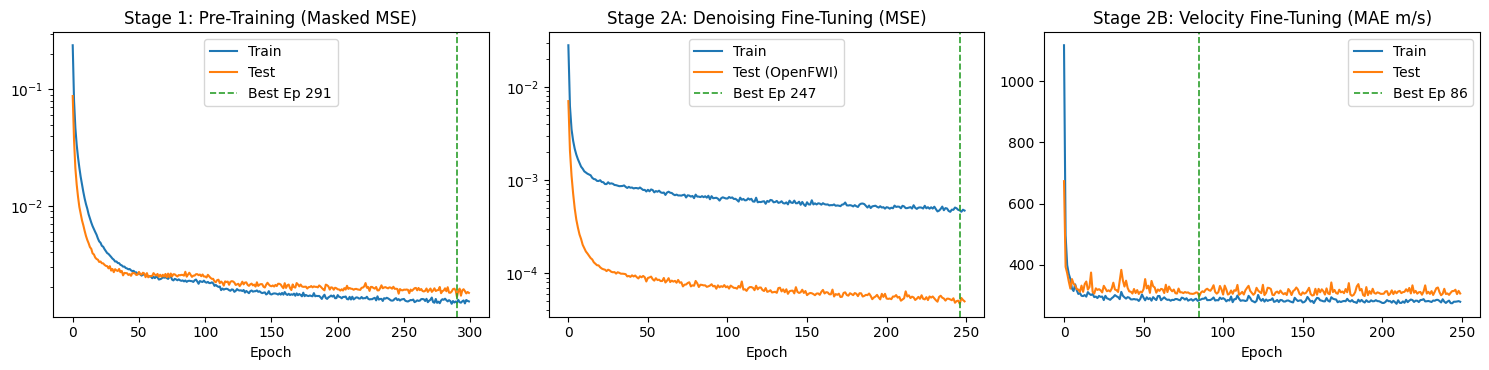

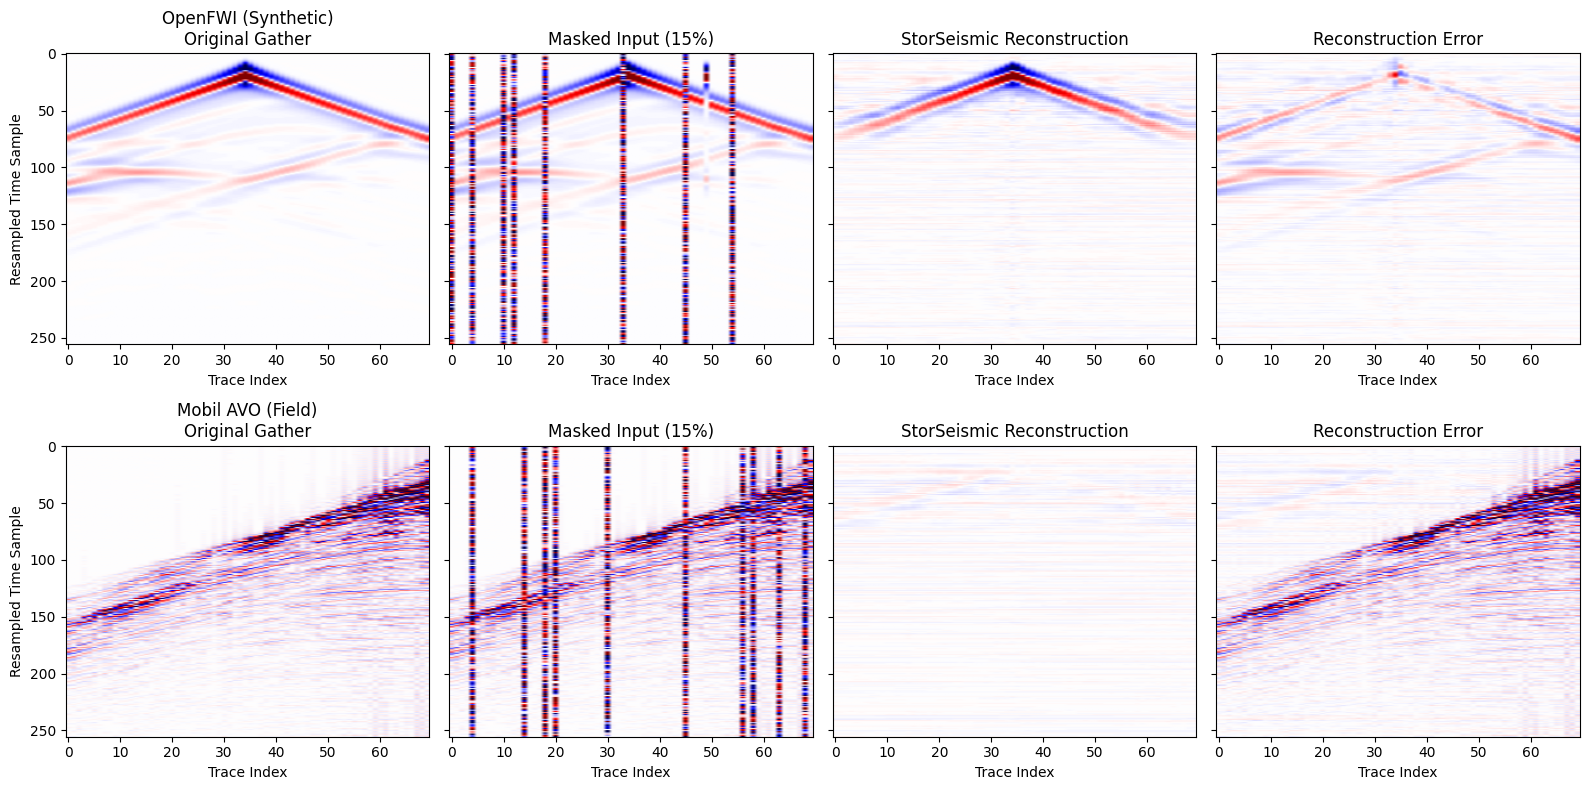

OpenFWI Denoise (sigma=0.15): Input SNR=-11.42 dB -> Output SNR=15.49 dB


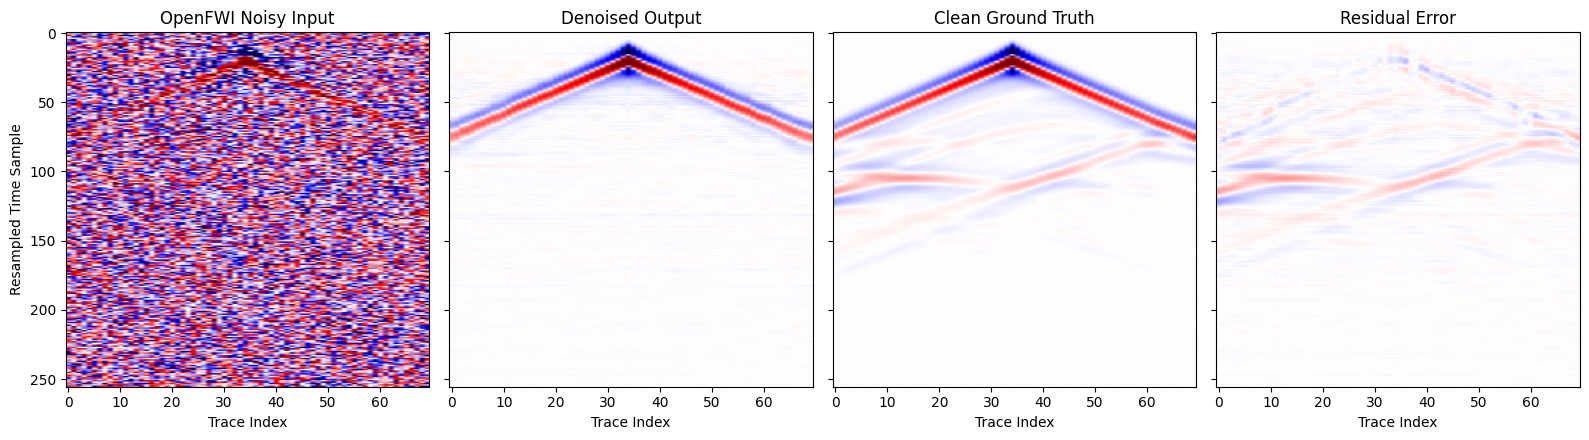

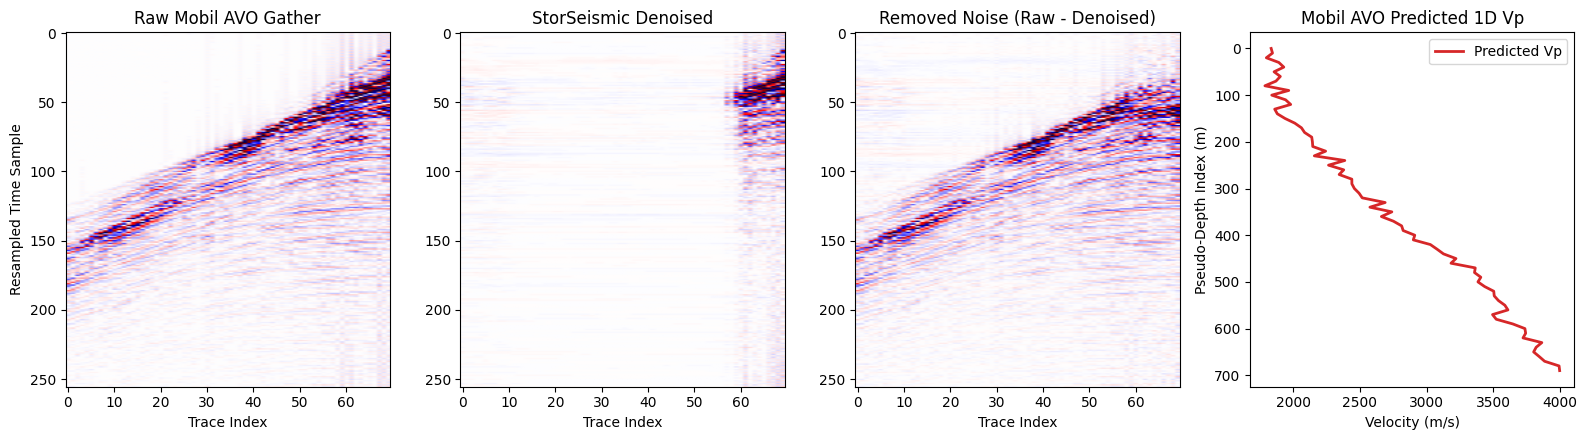

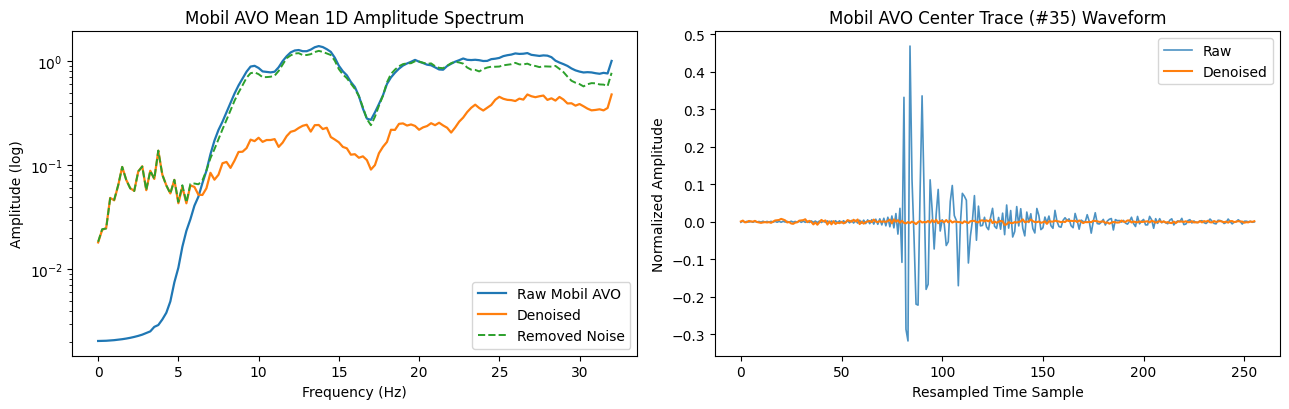

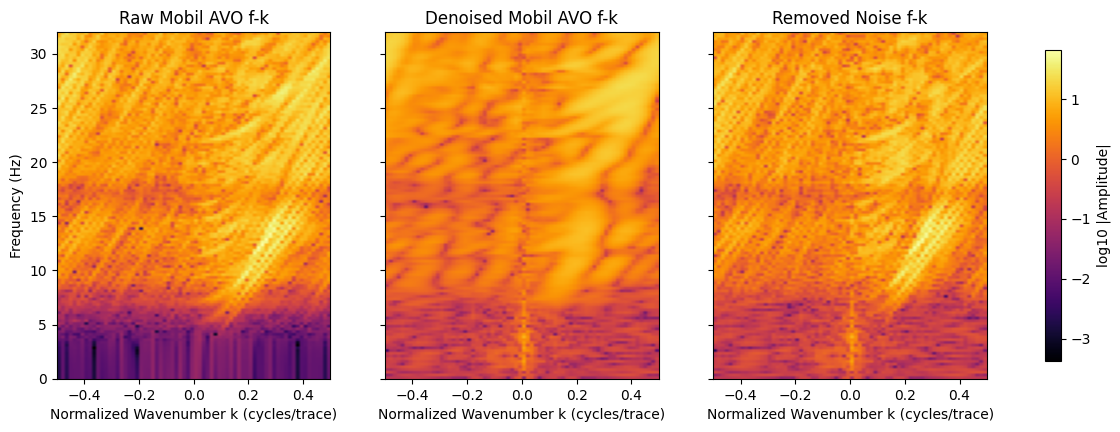

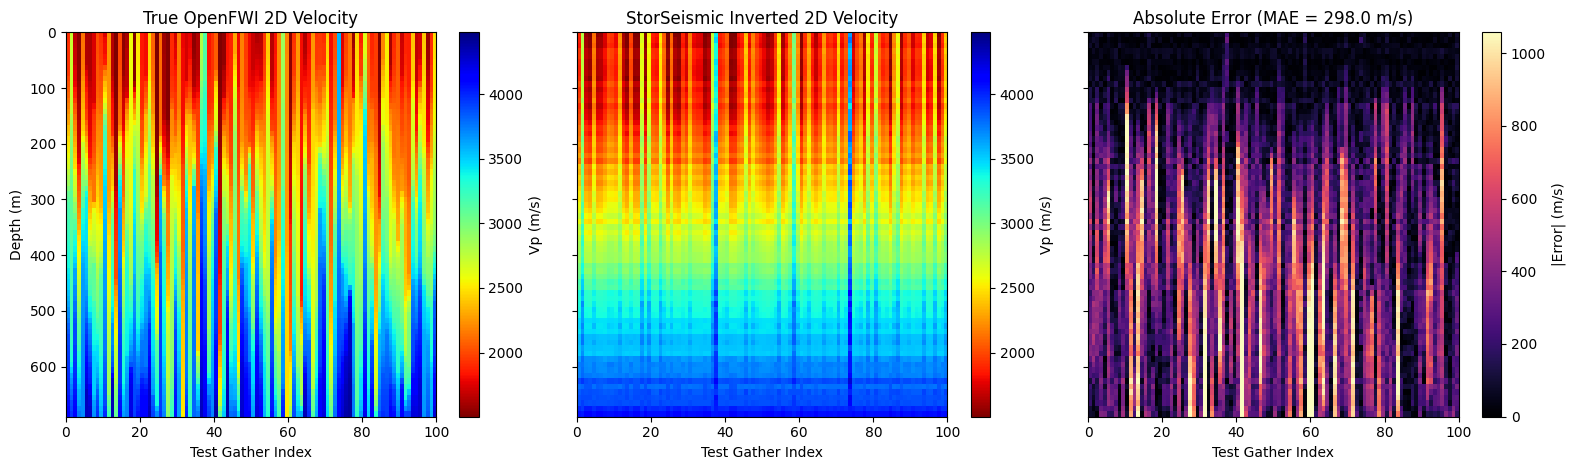

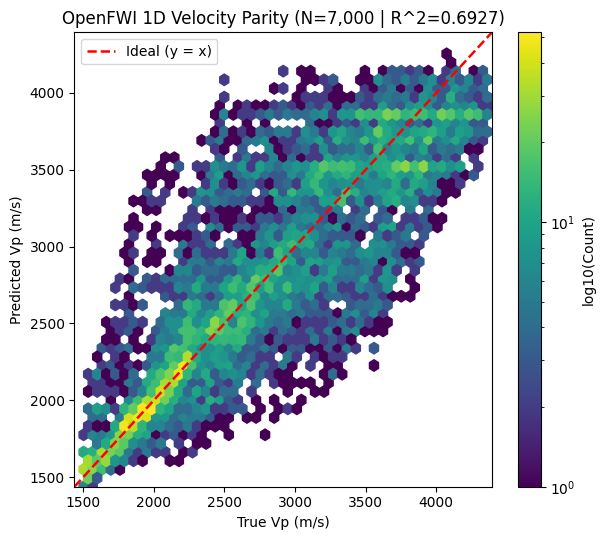

Zero-Shot Mobil AVO Interpolation SNR (dB) on Masked Traces:
  random20: Linear=-2.68 | Cubic=-5.08 | StorSeismic=-0.04 dB
  gap5: Linear=-2.66 | Cubic=-9.98 | StorSeismic=-0.08 dB


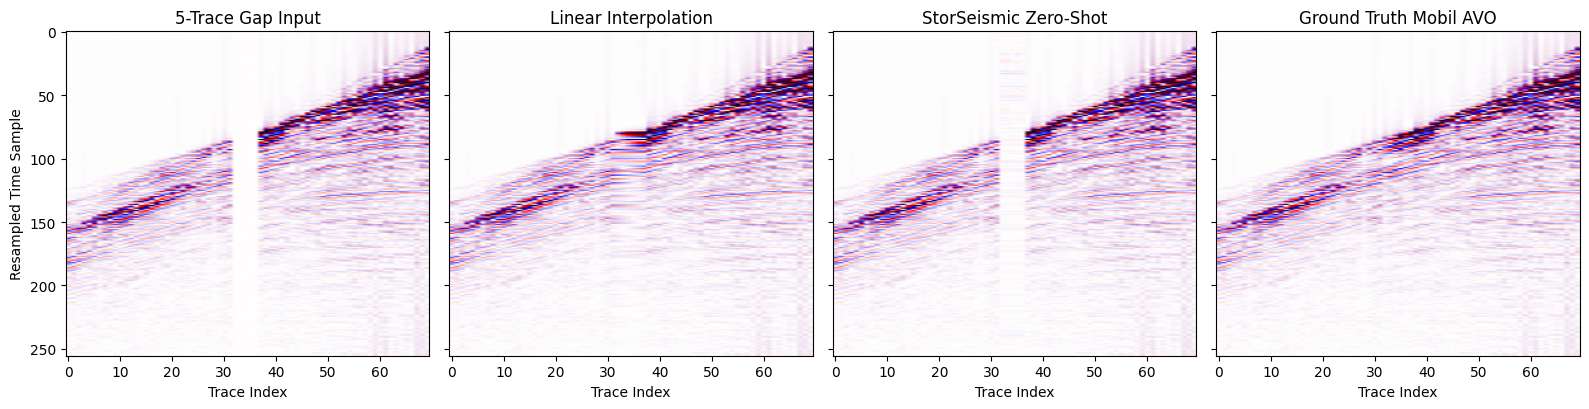

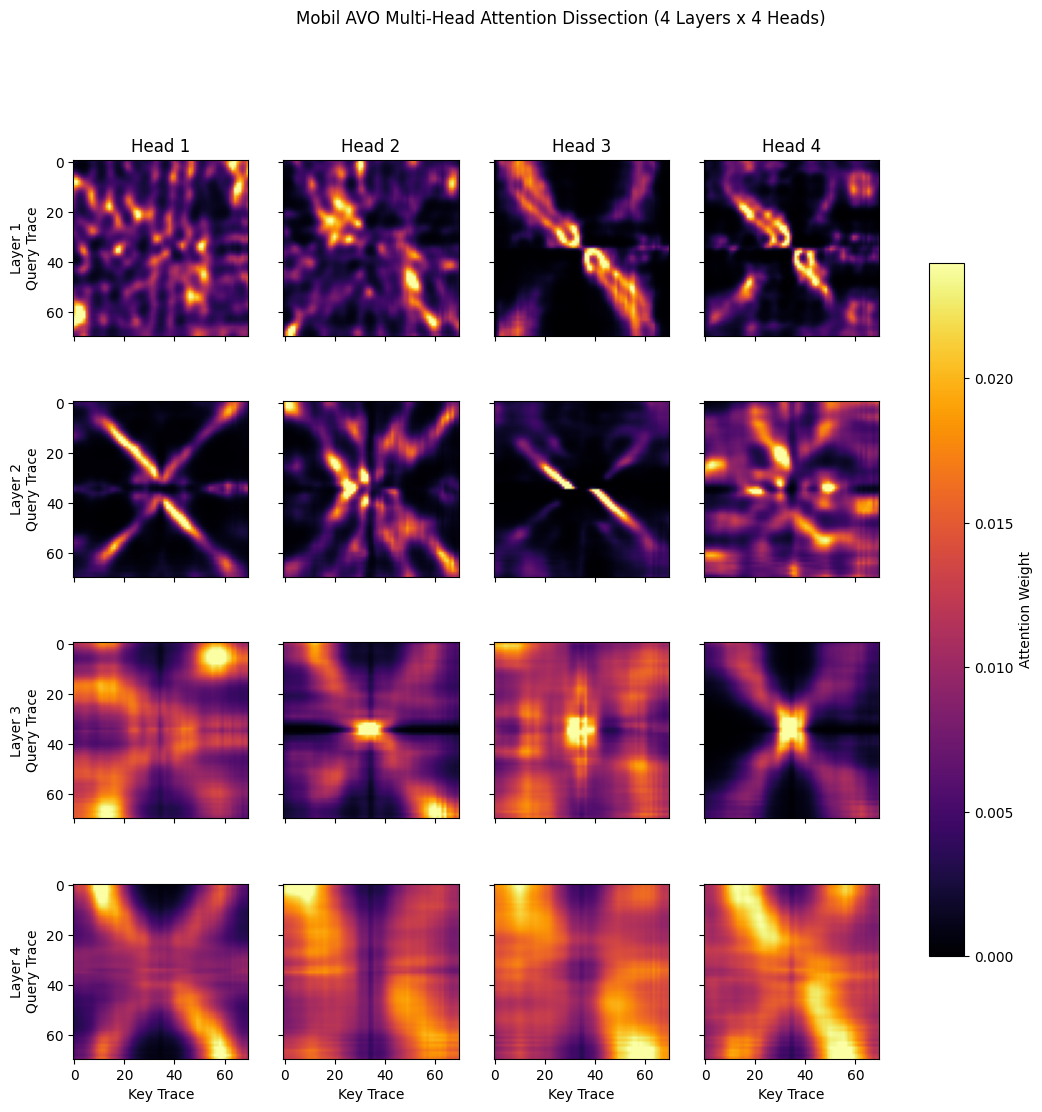

Saved bundle & config to ./results/mobil_openfwi_section4
Test Metrics: Denoise MSE=0.000048 (SNR=15.49 dB) | Vel MAE=298.0 m/s (R^2=0.6927)


In [8]:
# ==============================================================================
# 1. INFERENCE ON UNSEEN MOBIL AVO TEST SHOT GATHER
# ==============================================================================
sample_idx = min(5, len(f_test) - 1)
field_shot = f_test[sample_idx]
field_tensor = torch.tensor(field_shot, dtype=torch.float32).unsqueeze(0).to(device)

model_pretrain.eval()
model_denoise.eval()
model_vel.eval()

with torch.no_grad():
    field_denoised = model_denoise(field_tensor).squeeze(0).cpu().numpy()
    field_vel_norm = model_vel(field_tensor)[0, 0, :].cpu().numpy()

field_removed_noise = field_shot - field_denoised
field_vel_pred = field_vel_norm * (VEL_MAX - VEL_MIN) + VEL_MIN
vmin, vmax = -0.35, 0.35

# Reflection correlation & removed energy diagnostics on unseen Mobil test set
field_corrs, field_rem_pcts = [], []
with torch.no_grad():
    for g in f_test:
        pred_g = model_denoise(torch.tensor(g[None], dtype=torch.float32, device=device)).squeeze(0).cpu().numpy()
        g_f, p_f = g.ravel(), pred_g.ravel()
        if np.std(g_f) > 1e-12 and np.std(p_f) > 1e-12:
            r = float(np.corrcoef(g_f, p_f)[0, 1])
        else:
            r = 0.0
        rem_pct = float(100.0 * np.sum((g - pred_g) ** 2) / (np.sum(g ** 2) + 1e-12))
        field_corrs.append(r)
        field_rem_pcts.append(rem_pct)

print(f"Mobil AVO Field Denoising Diagnostics (N={len(f_test)} unseen test gathers):")
print(f"  Raw-Denoised Correlation (r) : {np.mean(field_corrs):.4f} +/- {np.std(field_corrs):.4f}")
print(f"  Removed Energy (%)           : {np.mean(field_rem_pcts):.2f}%")

# ==============================================================================
# 2. TRAINING CURVES & PRE-TRAINING RECONSTRUCTION
# ==============================================================================
if len(pt_train_losses) > 0:
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
    axes[0].plot(pt_train_losses, label="Train")
    axes[0].plot(pt_test_losses, label="Test")
    if best_pt_epoch > 0:
        axes[0].axvline(best_pt_epoch - 1, color="tab:green", ls="--", lw=1.2, label=f"Best Ep {best_pt_epoch}")
    axes[0].set_title("Stage 1: Pre-Training (Masked MSE)")
    axes[0].set_xlabel("Epoch")
    axes[0].set_yscale("log")
    axes[0].legend()

    axes[1].plot(den_train_losses, label="Train")
    axes[1].plot(den_test_losses, label="Test (OpenFWI)")
    if best_den_epoch > 0:
        axes[1].axvline(best_den_epoch - 1, color="tab:green", ls="--", lw=1.2, label=f"Best Ep {best_den_epoch}")
    axes[1].set_title("Stage 2A: Denoising Fine-Tuning (MSE)")
    axes[1].set_xlabel("Epoch")
    axes[1].set_yscale("log")
    axes[1].legend()

    axes[2].plot([l * (VEL_MAX - VEL_MIN) for l in vel_train_losses], label="Train")
    axes[2].plot([l * (VEL_MAX - VEL_MIN) for l in vel_test_losses], label="Test")
    if best_vel_epoch > 0:
        axes[2].axvline(best_vel_epoch - 1, color="tab:green", ls="--", lw=1.2, label=f"Best Ep {best_vel_epoch}")
    axes[2].set_title("Stage 2B: Velocity Fine-Tuning (MAE m/s)")
    axes[2].set_xlabel("Epoch")
    axes[2].legend()

    plt.tight_layout()
    plt.savefig(os.path.join(SAVE_DIR, "report_1_training_curves.png"), dpi=300)
    plt.show()

# Pre-Training Masked Trace Reconstruction
np.random.seed(SEED)
pt_eval_ds = PretrainDataset(s_test, f_test, MASK_RATIO, augment=False, gap_aug_prob=0.0)
fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharey=True)
s_idx_eval = min(sample_idx, len(s_test) - 1)
f_idx_eval = len(s_test) + min(sample_idx, len(f_test) - 1)

for row, (idx, name) in enumerate([(s_idx_eval, "OpenFWI (Synthetic)"), (f_idx_eval, "Mobil AVO (Field)")]):
    x_m, lbl_m, msk = pt_eval_ds[idx]
    with torch.no_grad():
        rec_m = model_pretrain(x_m.unsqueeze(0).to(device)).squeeze(0).cpu().numpy()
    orig_m = lbl_m.numpy()
    masked_in = x_m.numpy()
    err_m = orig_m - rec_m

    for col, (img, ttl) in enumerate([
        (orig_m.T, f"{name}\nOriginal Gather"),
        (masked_in.T, "Masked Input (15%)"),
        (rec_m.T, "StorSeismic Reconstruction"),
        (err_m.T, "Reconstruction Error"),
    ]):
        axes[row, col].imshow(img, aspect="auto", cmap="seismic", vmin=vmin, vmax=vmax)
        axes[row, col].set_title(ttl)
        axes[row, col].set_xlabel("Trace Index")
    axes[row, 0].set_ylabel("Resampled Time Sample")

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "report_2_pretrain_reconstruction.png"), dpi=300)
plt.show()

# ==============================================================================
# 3. SYNTHETIC DENOISING & VELOCITY PREDICTIONS
# ==============================================================================
np.random.seed(SEED)
all_noisy_s, all_clean_s = [], []
for clean_g in s_test:
    noise = np.random.normal(0.0, 0.15, size=clean_g.shape).astype(np.float32)
    all_noisy_s.append(normalize_gather(clean_g + noise))
    all_clean_s.append(clean_g)
all_noisy_s = np.array(all_noisy_s, dtype=np.float32)
all_clean_s = np.array(all_clean_s, dtype=np.float32)

with torch.no_grad():
    frozen_den_synth_preds = model_denoise(torch.tensor(all_noisy_s, device=device)).cpu().numpy()
    frozen_den_field_preds = model_denoise(torch.tensor(f_test, dtype=torch.float32, device=device)).cpu().numpy()
    frozen_vel_synth_preds = model_vel(torch.tensor(s_test, dtype=torch.float32, device=device))[:, 0, :].cpu().numpy() * (VEL_MAX - VEL_MIN) + VEL_MIN
    frozen_vel_field_preds = model_vel(torch.tensor(f_test, dtype=torch.float32, device=device))[:, 0, :].cpu().numpy() * (VEL_MAX - VEL_MIN) + VEL_MIN

v_test_ms = v_test * (VEL_MAX - VEL_MIN) + VEL_MIN
frozen_den_mse = float(np.mean((frozen_den_synth_preds - all_clean_s) ** 2))
frozen_vel_mae = float(np.mean(np.abs(frozen_vel_synth_preds - v_test_ms)))

def compute_snr_db(clean, est):
    sig_pow = np.sum(clean ** 2)
    noise_pow = np.sum((clean - est) ** 2) + 1e-12
    return float(10.0 * np.log10((sig_pow + 1e-12) / noise_pow))

snr_in_list = [compute_snr_db(c, n) for c, n in zip(all_clean_s, all_noisy_s)]
snr_out_list = [compute_snr_db(c, p) for c, p in zip(all_clean_s, frozen_den_synth_preds)]
print(f"OpenFWI Denoise (sigma=0.15): Input SNR={np.mean(snr_in_list):.2f} dB -> Output SNR={np.mean(snr_out_list):.2f} dB")

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5), sharey=True)
for ax, img, ttl in [
    (axes[0], all_noisy_s[s_idx_eval].T, "OpenFWI Noisy Input"),
    (axes[1], frozen_den_synth_preds[s_idx_eval].T, "Denoised Output"),
    (axes[2], all_clean_s[s_idx_eval].T, "Clean Ground Truth"),
    (axes[3], (all_clean_s[s_idx_eval] - frozen_den_synth_preds[s_idx_eval]).T, "Residual Error"),
]:
    ax.imshow(img, aspect="auto", cmap="seismic", vmin=vmin, vmax=vmax)
    ax.set_title(ttl)
    ax.set_xlabel("Trace Index")
axes[0].set_ylabel("Resampled Time Sample")
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "report_3_synth_denoise.png"), dpi=300)
plt.show()

# ==============================================================================
# 4. UNSEEN FIELD DATA INFERENCE & SPECTRUM
# ==============================================================================
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, img, ttl in [
    (axes[0], field_shot.T, "Raw Mobil AVO Gather"),
    (axes[1], field_denoised.T, "StorSeismic Denoised"),
    (axes[2], field_removed_noise.T, "Removed Noise (Raw - Denoised)"),
]:
    ax.imshow(img, aspect="auto", cmap="seismic", vmin=vmin, vmax=vmax)
    ax.set_title(ttl)
    ax.set_xlabel("Trace Index")
axes[0].set_ylabel("Resampled Time Sample")

depth_axis = np.arange(vel_dim) * 10.0
axes[3].plot(field_vel_pred, depth_axis, color="tab:red", lw=2.0, label="Predicted Vp")
axes[3].invert_yaxis()
axes[3].set_title("Mobil AVO Predicted 1D Vp")
axes[3].set_xlabel("Velocity (m/s)")
axes[3].set_ylabel("Pseudo-Depth Index (m)")
axes[3].legend()
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "report_4_field_inference.png"), dpi=300)
plt.show()

# 1D Amplitude Spectrum + Center Trace Waveform
fs_field = float(FS_MOBIL)
freqs = np.fft.rfftfreq(N_TIME, d=1.0 / fs_field)
raw_spec = np.mean(np.abs(np.fft.rfft(field_shot, axis=1)), axis=0)
den_spec = np.mean(np.abs(np.fft.rfft(field_denoised, axis=1)), axis=0)
rem_spec = np.mean(np.abs(np.fft.rfft(field_removed_noise, axis=1)), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].semilogy(freqs, raw_spec + 1e-4, label="Raw Mobil AVO", lw=1.6)
axes[0].semilogy(freqs, den_spec + 1e-4, label="Denoised", lw=1.6)
axes[0].semilogy(freqs, rem_spec + 1e-4, label="Removed Noise", lw=1.4, linestyle="--")
axes[0].set_title("Mobil AVO Mean 1D Amplitude Spectrum")
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Amplitude (log)")
axes[0].legend()

center_tr = 35
axes[1].plot(field_shot[center_tr], label="Raw", lw=1.2, alpha=0.8)
axes[1].plot(field_denoised[center_tr], label="Denoised", lw=1.5)
axes[1].set_title("Mobil AVO Center Trace (#35) Waveform")
axes[1].set_xlabel("Resampled Time Sample")
axes[1].set_ylabel("Normalized Amplitude")
axes[1].legend()
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "report_5_field_spectrum_waveform.png"), dpi=300)
plt.show()

# ==============================================================================
# 5. f-k SPECTRUM DECOMPOSITION, 2D VELOCITY CROSS-SECTION & PARITY SCATTER
# ==============================================================================
f_nyq = fs_field / 2.0
k_nyq = 0.5
fk_raw = np.abs(np.fft.fftshift(np.fft.fft2(field_shot.T)))
fk_den = np.abs(np.fft.fftshift(np.fft.fft2(field_denoised.T)))
fk_res = np.abs(np.fft.fftshift(np.fft.fft2(field_removed_noise.T)))

mid_f = fk_raw.shape[0] // 2
fk_raw_pos = np.log10(fk_raw[mid_f:, :] + 1e-4)
fk_den_pos = np.log10(fk_den[mid_f:, :] + 1e-4)
fk_res_pos = np.log10(fk_res[mid_f:, :] + 1e-4)
fk_vmin = min(fk_raw_pos.min(), fk_den_pos.min(), fk_res_pos.min())
fk_vmax = max(fk_raw_pos.max(), fk_den_pos.max(), fk_res_pos.max())

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, (spec, ttl) in zip(axes, [
    (fk_raw_pos, "Raw Mobil AVO f-k"),
    (fk_den_pos, "Denoised Mobil AVO f-k"),
    (fk_res_pos, "Removed Noise f-k"),
]):
    im = ax.imshow(spec, aspect="auto", origin="lower", cmap="inferno",
                   extent=[-k_nyq, k_nyq, 0, f_nyq], vmin=fk_vmin, vmax=fk_vmax)
    ax.set_title(ttl)
    ax.set_xlabel("Normalized Wavenumber k (cycles/trace)")
axes[0].set_ylabel("Frequency (Hz)")
fig.colorbar(im, ax=axes.ravel().tolist(), label="log10 |Amplitude|", shrink=0.9)
plt.savefig(os.path.join(SAVE_DIR, "report_6_fk_spectrum_field.png"), dpi=300, bbox_inches="tight")
plt.show()

# 2D Multi-Gather Inverted Velocity Cross-Section
vel_abs_err = np.abs(frozen_vel_synth_preds - v_test_ms)
depth_m = np.arange(vel_dim) * 10.0

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
im0 = axes[0].imshow(v_test_ms.T, aspect="auto", cmap="jet_r",
                     extent=[0, len(v_test_ms), depth_m[-1], depth_m[0]], vmin=VEL_MIN, vmax=VEL_MAX)
axes[0].set_title("True OpenFWI 2D Velocity")
axes[0].set_xlabel("Test Gather Index")
axes[0].set_ylabel("Depth (m)")
fig.colorbar(im0, ax=axes[0], label="Vp (m/s)")

im1 = axes[1].imshow(frozen_vel_synth_preds.T, aspect="auto", cmap="jet_r",
                     extent=[0, len(v_test_ms), depth_m[-1], depth_m[0]], vmin=VEL_MIN, vmax=VEL_MAX)
axes[1].set_title("StorSeismic Inverted 2D Velocity")
axes[1].set_xlabel("Test Gather Index")
fig.colorbar(im1, ax=axes[1], label="Vp (m/s)")

im2 = axes[2].imshow(vel_abs_err.T, aspect="auto", cmap="magma",
                     extent=[0, len(v_test_ms), depth_m[-1], depth_m[0]], vmin=0, vmax=np.percentile(vel_abs_err, 98))
axes[2].set_title(f"Absolute Error (MAE = {frozen_vel_mae:.1f} m/s)")
axes[2].set_xlabel("Test Gather Index")
fig.colorbar(im2, ax=axes[2], label="|Error| (m/s)")
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "report_7_2d_velocity_cross_section.png"), dpi=300, bbox_inches="tight")
plt.show()

# Velocity Parity Density Scatter
y_true_flat = v_test_ms.ravel()
y_pred_flat = frozen_vel_synth_preds.ravel()
vel_r2 = float(1.0 - np.sum((y_true_flat - y_pred_flat) ** 2) / (np.sum((y_true_flat - np.mean(y_true_flat)) ** 2) + 1e-12))

fig, ax = plt.subplots(figsize=(6.2, 5.5))
hb = ax.hexbin(y_true_flat, y_pred_flat, gridsize=45, cmap="viridis", mincnt=1, bins="log")
lims = [min(y_true_flat.min(), y_pred_flat.min()), max(y_true_flat.max(), y_pred_flat.max())]
ax.plot(lims, lims, "r--", lw=1.8, label="Ideal (y = x)")
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("True Vp (m/s)")
ax.set_ylabel("Predicted Vp (m/s)")
ax.set_title(f"OpenFWI 1D Velocity Parity (N={len(y_true_flat):,} | R^2={vel_r2:.4f})")
ax.legend(loc="upper left")
fig.colorbar(hb, ax=ax, label="log10(Count)")
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "report_8_velocity_parity_scatter.png"), dpi=300, bbox_inches="tight")
plt.show()

# ==============================================================================
# 6. ZERO-SHOT DEAD-TRACE INTERPOLATION (EXP B2 PROTOCOL)
# ==============================================================================
def classical_interp(gather_2d, mask_bool, kind="linear"):
    x_all = np.arange(gather_2d.shape[0])
    x_obs = x_all[~mask_bool]
    y_obs = gather_2d[~mask_bool]
    fn = interp1d(x_obs, y_obs, kind=kind, axis=0, bounds_error=False, fill_value="extrapolate")
    out = gather_2d.copy()
    out[mask_bool] = fn(x_all[mask_bool])
    return out

def zeroshot_interp(model, gather_2d, mask_bool, seed=42, n_avg=5):
    """Zero-shot MLM trace interpolation averaged over n_avg Gaussian mask draws to reduce variance."""
    rng_i = np.random.default_rng(seed)
    preds = []
    with torch.no_grad():
        for _ in range(n_avg):
            x_in = gather_2d.copy()
            x_in[mask_bool] = rng_i.normal(0.0, 0.3, size=(int(mask_bool.sum()), gather_2d.shape[1])).astype(np.float32)
            pred = model(torch.tensor(x_in[None], dtype=torch.float32, device=device)).cpu().numpy()[0]
            preds.append(pred[mask_bool])
    out = gather_2d.copy()
    out[mask_bool] = np.mean(preds, axis=0)
    return out

rng_b2 = np.random.default_rng(2025)
b2_results = {"random20": {"linear": [], "cubic": [], "storseismic": []},
              "gap5": {"linear": [], "cubic": [], "storseismic": []}}

for idx_g, g in enumerate(f_test):
    m_rand = np.zeros(N_TRACES, dtype=bool)
    m_rand[rng_b2.choice(np.arange(1, N_TRACES - 1), size=int(0.2 * N_TRACES), replace=False)] = True
    m_gap = np.zeros(N_TRACES, dtype=bool)
    m_gap[32:37] = True
    for name_s, m_s in [("random20", m_rand), ("gap5", m_gap)]:
        for m_name, pred_g in [
            ("linear", classical_interp(g, m_s, "linear")),
            ("cubic", classical_interp(g, m_s, "cubic")),
            ("storseismic", zeroshot_interp(model_pretrain, g, m_s, seed=100 + idx_g)),
        ]:
            b2_results[name_s][m_name].append(compute_snr_db(g[m_s], pred_g[m_s]))

print("Zero-Shot Mobil AVO Interpolation SNR (dB) on Masked Traces:")
for name_s in ["random20", "gap5"]:
    print(f"  {name_s}: Linear={np.mean(b2_results[name_s]['linear']):.2f} | "
          f"Cubic={np.mean(b2_results[name_s]['cubic']):.2f} | "
          f"StorSeismic={np.mean(b2_results[name_s]['storseismic']):.2f} dB")

m_gap_vis = np.zeros(N_TRACES, dtype=bool); m_gap_vis[32:37] = True
vis_lin = classical_interp(field_shot, m_gap_vis, "linear")
vis_ss = zeroshot_interp(model_pretrain, field_shot, m_gap_vis, seed=42)

fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), sharey=True)
g_in = field_shot.copy(); g_in[m_gap_vis] = 0.0
for ax, img, ttl in [
    (axes[0], g_in.T, "5-Trace Gap Input"),
    (axes[1], vis_lin.T, "Linear Interpolation"),
    (axes[2], vis_ss.T, "StorSeismic Zero-Shot"),
    (axes[3], field_shot.T, "Ground Truth Mobil AVO"),
]:
    ax.imshow(img, aspect="auto", cmap="seismic", vmin=vmin, vmax=vmax)
    ax.set_title(ttl)
    ax.set_xlabel("Trace Index")
axes[0].set_ylabel("Resampled Time Sample")
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "report_9_zeroshot_interpolation.png"), dpi=300)
plt.show()

# ==============================================================================
# 7. SELF-ATTENTION MAP VISUALIZATION (4x4 MULTI-HEAD GRID)
# ==============================================================================
with torch.no_grad():
    _, attn_heads = model_pretrain.forward_with_attention(field_tensor, average_heads=False)

fig, axes = plt.subplots(NUM_LAYERS, NUM_HEADS, figsize=(13, 12), sharex=True, sharey=True)
for l_idx in range(NUM_LAYERS):
    for h_idx in range(NUM_HEADS):
        ax = axes[l_idx, h_idx]
        amap = attn_heads[l_idx][0, h_idx]
        im = ax.imshow(amap, cmap="inferno", vmin=0, vmax=np.percentile(amap, 99))
        if l_idx == 0:
            ax.set_title(f"Head {h_idx + 1}")
        if h_idx == 0:
            ax.set_ylabel(f"Layer {l_idx + 1}\nQuery Trace")
        if l_idx == NUM_LAYERS - 1:
            ax.set_xlabel("Key Trace")

fig.suptitle("Mobil AVO Multi-Head Attention Dissection (4 Layers x 4 Heads)", y=0.995)
fig.colorbar(im, ax=axes.ravel().tolist(), label="Attention Weight", shrink=0.75)
plt.savefig(os.path.join(SAVE_DIR, "report_10_multihead_attention.png"), dpi=300, bbox_inches="tight")
plt.show()

# Save evaluation bundle & config
bundle_path = os.path.join(SAVE_DIR, "ablation_frozen_bundle.npz")
np.savez_compressed(
    bundle_path,
    s_train=s_train, s_test=s_test, f_train=f_train, f_test=f_test,
    v_train=v_train, v_test=v_test,
    frozen_den_synth_preds=frozen_den_synth_preds,
    frozen_den_field_preds=frozen_den_field_preds,
    frozen_vel_synth_preds=frozen_vel_synth_preds,
    frozen_vel_field_preds=frozen_vel_field_preds,
)

config = {
    "SEED": SEED, "N_TRACES": N_TRACES, "N_TIME": N_TIME,
    "HIDDEN_DIM": HIDDEN_DIM, "NUM_LAYERS": NUM_LAYERS, "NUM_HEADS": NUM_HEADS,
    "MASK_RATIO": MASK_RATIO, "LR": LR,
    "DENOISE_FIELD_MIX_RATIO": DENOISE_FIELD_MIX_RATIO,
    "PRETRAIN_EPOCHS": PRETRAIN_EPOCHS,
    "FINETUNE_DENOISE_EPOCHS": FINETUNE_DENOISE_EPOCHS,
    "FINETUNE_VEL_EPOCHS": FINETUNE_VEL_EPOCHS,
    "best_pt_epoch": best_pt_epoch,
    "best_den_epoch": best_den_epoch,
    "best_vel_epoch": best_vel_epoch,
    "VEL_MIN": VEL_MIN, "VEL_MAX": VEL_MAX,
    "denoise_snr_out_db": float(np.mean(snr_out_list)),
    "frozen_test_denoise_mse": frozen_den_mse,
    "frozen_test_vel_mae_ms": frozen_vel_mae,
    "frozen_test_vel_r2": vel_r2,
    "field_corr_r": float(np.mean(field_corrs)),
    "field_removed_energy_pct": float(np.mean(field_rem_pcts)),
    "b2_random20_linear_db": float(np.mean(b2_results["random20"]["linear"])),
    "b2_random20_cubic_db": float(np.mean(b2_results["random20"]["cubic"])),
    "b2_random20_storseismic_db": float(np.mean(b2_results["random20"]["storseismic"])),
    "b2_gap5_linear_db": float(np.mean(b2_results["gap5"]["linear"])),
    "b2_gap5_cubic_db": float(np.mean(b2_results["gap5"]["cubic"])),
    "b2_gap5_storseismic_db": float(np.mean(b2_results["gap5"]["storseismic"])),
}
with open(os.path.join(SAVE_DIR, "ablation_config.json"), "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2)

print(f"Saved bundle & config to {SAVE_DIR}")
print(f"Test Metrics: Denoise MSE={frozen_den_mse:.6f} (SNR={np.mean(snr_out_list):.2f} dB) | Vel MAE={frozen_vel_mae:.1f} m/s (R^2={vel_r2:.4f})")